# 02 – The Score That Wasn't

> **Project notebooks:** [01 Exploration](01_exploration.ipynb) · [02 The score that wasn't](02_the_score_that_wasnt.ipynb)

In notebook 01 we found that 86% of the rows are copies: 6,000 customer profiles repeated 27 to 40 times. In this notebook we find out what that does to a model:

1. How to measure a model when one class is rare
2. The impressive result
3. Where the score comes from
4. A "model" that knows nothing about loans
5. Honest evaluation: keep copies together
6. A second honest check: one row per customer
7. Were the patterns in notebook 01 real?
8. What it would mean for a bank
9. A checklist for your own projects
10. Conclusions

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.compose import make_column_transformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)  # hide a harmless seaborn/pandas version notice
sns.set_theme(style="whitegrid", palette="Set2")

df = pd.read_csv("../data/Training.csv")
features = [c for c in df.columns if c not in ("Id", "Risk_Flag")]
df["Profile"] = df.groupby(features, sort=False).ngroup()          # same number for all copies of a customer
df["Copies"] = df.groupby("Profile")["Id"].transform("size")
y = df["Risk_Flag"].to_numpy()

# Random Forest works with numbers, so each text category gets a number
X_codes = df[features].copy()
for column in X_codes.select_dtypes("object"):
    X_codes[column] = X_codes[column].astype("category").cat.codes

print(f"Rows: {len(df):,}, different customers: {df['Profile'].nunique():,}, default rate: {y.mean():.1%}")

Rows: 252,000, different customers: 42,007, default rate: 12.3%


## 1. How to measure a model when one class is rare

In notebook 01 we saw the **accuracy trap**: saying "nobody defaults" is 87.7% accurate and useless. So we use two measures that are not fooled by imbalance. Both work with the model's **risk score** (its predicted probability of default) instead of a yes/no answer.

| Measure | Question it answers | Useless model | Perfect model |
|---|---|---|---|
| **ROC AUC** | Pick one customer who defaulted and one who did not. How often does the model give the defaulter the higher risk score? | **0.5** (a coin flip) | 1.0 |
| **Average precision (AP)** | When we go down the list from highest to lowest risk, how pure is the top of the list? | **0.123** (the default rate: picking customers at random) | 1.0 |

AUC is the most common measure for credit risk models. In practice, values around 0.7 to 0.8 are typical for a useful credit model, and values above 0.9 are rare and deserve suspicion.

## 2. The impressive result

We start the usual way: a Random Forest and 5‑fold cross‑validation with a **random** split, exactly as in the Titanic project. `StratifiedKFold` keeps the default rate the same in every fold.

In [2]:
%%time
forest = RandomForestClassifier(n_estimators=200, n_jobs=-1, random_state=42)
random_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

random_split_scores = cross_val_predict(forest, X_codes, y, cv=random_cv, method="predict_proba")[:, 1]

print(f"Random split:  ROC AUC {roc_auc_score(y, random_split_scores):.3f}, "
      f"average precision {average_precision_score(y, random_split_scores):.3f}")

Random split:  ROC AUC 0.938, average precision 0.600
CPU times: user 10.2 s, sys: 1.51 s, total: 11.7 s
Wall time: 24 s


An AUC of **0.94**. By the standards of credit risk this is an outstanding model, better than what banks achieve with far richer data such as payment histories. If we stopped here, we would write a proud README.

But an outstanding score from a dataset whose features showed only weak patterns in notebook 01 should make us suspicious. Where does it come from?

## 3. Where the score comes from

With a random split, the copies of each customer are scattered over all five folds. So when the model predicts a customer in the validation fold, it has almost always seen **an identical copy** of that customer, with its label, in the training folds.

We can check this directly: we split the out‑of‑fold predictions into customers that have copies and customers that appear only once.

In [3]:
has_copies = (df["Copies"] > 1).to_numpy()

seen_table = pd.DataFrame({
    "customers": [has_copies.sum(), (~has_copies).sum()],
    "ROC AUC": [roc_auc_score(y[has_copies], random_split_scores[has_copies]),
                roc_auc_score(y[~has_copies], random_split_scores[~has_copies])],
}, index=["Copied customers (a twin was in training)", "One-off customers (genuinely new)"])
seen_table.style.format({"customers": "{:,}", "ROC AUC": "{:.3f}"})

,customers,ROC AUC
Copied customers (a twin was in training),"215,993",0.961
One-off customers (genuinely new),"36,007",0.494


This table is the whole story in two lines:

- For the **copied customers**, whose twins were in the training folds, the AUC is **0.96**.
- For the **one‑off customers**, who are genuinely new to the model, the AUC is **0.49**: no better than a coin flip.

The impressive 0.94 overall is simply an average of "recognised" customers (86% of the rows) and "new" customers (14%). The model has learned nothing that helps with someone it has never seen.

## 4. A "model" that knows nothing about loans

To make the point unmistakable, we build the dumbest possible "model": a **lookup table**. For each customer it looks for identical customers in the training folds and predicts their average default rate. If it finds none, it predicts the overall default rate. It has no idea what income or age mean.

In [4]:
lookup_scores = np.zeros(len(df))
for train_index, valid_index in random_cv.split(X_codes, y):
    rate_per_profile = pd.Series(y[train_index]).groupby(df["Profile"].to_numpy()[train_index]).mean()
    lookup_scores[valid_index] = (df["Profile"].iloc[valid_index].map(rate_per_profile)
                                  .fillna(y[train_index].mean()).to_numpy())

print(f"Lookup table:   ROC AUC {roc_auc_score(y, lookup_scores):.3f}")
print(f"Random Forest:  ROC AUC {roc_auc_score(y, random_split_scores):.3f}")

Lookup table:   ROC AUC 0.939
Random Forest:  ROC AUC 0.938


The lookup table scores **the same** as the Random Forest. Everything the "outstanding" model achieved, a simple "have I seen this exact customer before?" achieves too.

The Random Forest did not learn to predict default. It learned to **recognise** customers, which deep trees are very good at: with enough splits, every unique combination of income, age and city gets its own leaf.

## 5. Honest evaluation: keep copies together

The fix is the same idea as the `GroupKFold` used in many real projects (for example, keeping all visits of one patient on the same side): **all copies of a customer must land in the same fold**. Then every validation customer is genuinely new to the model.

`StratifiedGroupKFold` does exactly that: it splits by group (here the `Profile` number) and still keeps the default rate similar in every fold.

In [5]:
%%time
group_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
grouped_scores = cross_val_predict(forest, X_codes, y, cv=group_cv, groups=df["Profile"], method="predict_proba")[:, 1]

print(f"Grouped split: ROC AUC {roc_auc_score(y, grouped_scores):.3f}, "
      f"average precision {average_precision_score(y, grouped_scores):.3f}")

Grouped split: ROC AUC 0.497, average precision 0.123
CPU times: user 11.1 s, sys: 1.52 s, total: 12.6 s
Wall time: 25.1 s


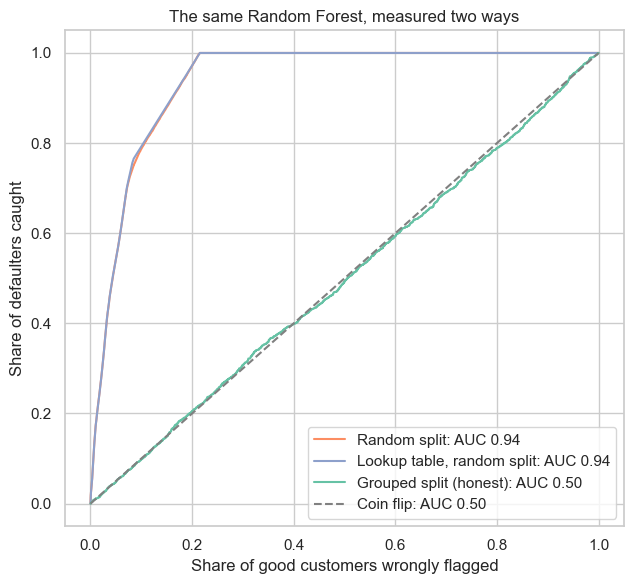

In [6]:
fig, ax = plt.subplots(figsize=(6.5, 6))
for scores, label, color in [(random_split_scores, "Random split", "C1"),
                             (lookup_scores, "Lookup table, random split", "C2"),
                             (grouped_scores, "Grouped split (honest)", "C0")]:
    false_alarm_rate, catch_rate, _ = roc_curve(y, scores)
    ax.plot(false_alarm_rate, catch_rate, color=color, label=f"{label}: AUC {roc_auc_score(y, scores):.2f}")
ax.plot([0, 1], [0, 1], color="grey", linestyle="--", label="Coin flip: AUC 0.50")
ax.set(title="The same Random Forest, measured two ways",
       xlabel="Share of good customers wrongly flagged", ylabel="Share of defaulters caught")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../images/roc_random_vs_grouped.png", dpi=120)
plt.show()

Once copies are kept together, the same Random Forest scores an AUC of **0.50** and an average precision of **0.123**, exactly the values of a model that guesses (see the table in section 1). Its ROC curve lies on top of the coin‑flip line.

Nothing about the model changed. Only the **evaluation** changed, from one that let the model recognise customers to one that matches how the model would really be used: on new customers.

## 6. A second honest check: one row per customer

Maybe the Random Forest is simply the wrong model for genuinely new customers. As a second check we remove the copies altogether, keep **one row per customer** (with the label most of its copies have), and try two different models with an ordinary split. Without copies, an ordinary split is honest again.

- **Logistic regression**: a simple linear model, with one‑hot encoding for the text columns. Rare cities (fewer than 20 customers) are grouped together.
- **Random Forest** with the same settings as above.

In [7]:
%%time
customers = df.groupby(features, as_index=False)["Risk_Flag"].mean()
customers["Risk_Flag"] = (customers["Risk_Flag"] >= 0.5).astype(int)
X_customers, y_customers = customers[features], customers["Risk_Flag"].to_numpy()

text_columns = X_customers.select_dtypes("object").columns.tolist()
number_columns = [c for c in features if c not in text_columns]
logistic = make_pipeline(
    make_column_transformer((OneHotEncoder(handle_unknown="ignore", min_frequency=20), text_columns),
                            (StandardScaler(), number_columns)),
    LogisticRegression(max_iter=2000),
)

X_customers_codes = X_customers.copy()
for column in text_columns:
    X_customers_codes[column] = X_customers_codes[column].astype("category").cat.codes

plain_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
one_row_results = {}
for name, model, X_input in [("Logistic regression", logistic, X_customers),
                             ("Random Forest", forest, X_customers_codes)]:
    scores = cross_val_predict(model, X_input, y_customers, cv=plain_cv, method="predict_proba")[:, 1]
    one_row_results[name] = {"ROC AUC": roc_auc_score(y_customers, scores),
                             "average precision": average_precision_score(y_customers, scores)}

print(f"Customers: {len(customers):,}, default rate: {y_customers.mean():.1%}")
pd.DataFrame(one_row_results).T.round(3)

Customers: 42,007, default rate: 19.1%
CPU times: user 3.35 s, sys: 1.54 s, total: 4.89 s
Wall time: 6.06 s


,ROC AUC,average precision
Logistic regression,0.509,0.195
Random Forest,0.498,0.187


Both models land at an AUC of about **0.5** again, and their average precision is close to the default rate among these customers (19.1%), which is what random guessing gives.

So it is not the choice of model. With one row per customer, neither a simple nor a flexible model finds any pattern that predicts default for a customer it has not seen. **The features in this dataset do not contain the information needed to predict loan default.**

(The default rate is higher here, 19.1% instead of 12.3%, because each customer now counts once, and the heavily copied profiles defaulted less often.)

## 7. Were the patterns in notebook 01 real?

In notebook 01 we saw small differences: younger customers and those new in their job defaulted a little more often. But those charts counted every copy, so a profile copied 40 times counted 40 times. Do the patterns survive when each customer counts once?

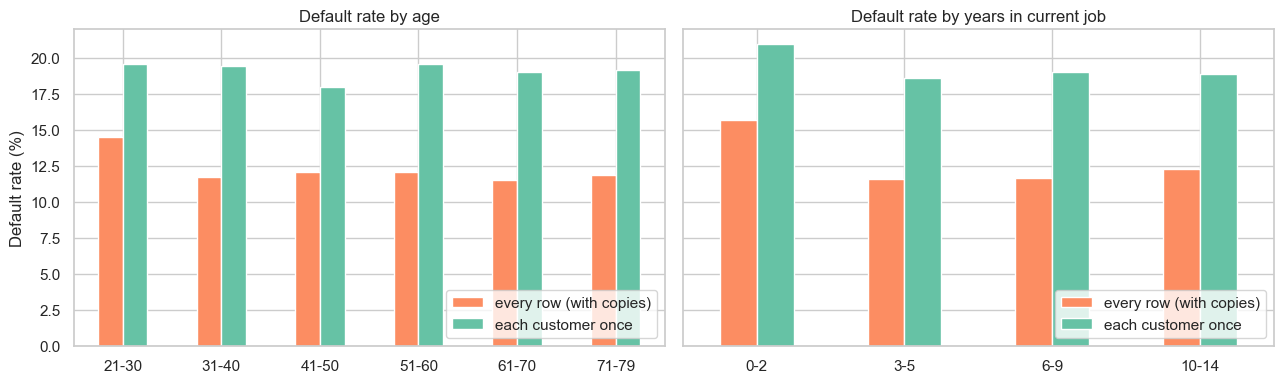

In [8]:
def rates_by(group_name, make_groups):
    with_copies = df["Risk_Flag"].groupby(make_groups(df), observed=True).mean()
    once_each = customers["Risk_Flag"].groupby(make_groups(customers), observed=True).mean()
    return pd.DataFrame({"every row (with copies)": with_copies, "each customer once": once_each}) * 100


age_groups = lambda d: pd.cut(d["Age"], [20, 30, 40, 50, 60, 70, 80], labels=["21-30", "31-40", "41-50", "51-60", "61-70", "71-79"])
job_groups = lambda d: pd.cut(d["CURRENT_JOB_YRS"], [-1, 2, 5, 9, 14], labels=["0-2", "3-5", "6-9", "10-14"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, (title, make_groups) in zip(axes, [("Age", age_groups), ("Years in current job", job_groups)]):
    rates_by(title, make_groups).plot.bar(ax=ax, color=["C1", "C0"])
    ax.set(title=f"Default rate by {title.lower()}", xlabel="", ylabel="Default rate (%)")
    ax.legend(loc="lower right")
    ax.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("../images/patterns_with_and_without_copies.png", dpi=120)
plt.show()

Counting each customer once changes the picture:

- **Age:** the pattern **disappears**. Customers aged 21–30 default at 19.5%, the same as most other age groups (18–19.5%). The "younger customers are riskier" pattern of notebook 01 was created by which profiles happened to be copied most.
- **Years in the current job:** a small difference **remains**. Customers in their first two years default at 20.9%, the others at about 19%. With almost 6,000 customers in that group this difference is probably real, but it is far too small to build a useful model on.

**Lesson:** duplicates do not only inflate model scores. They also distort simple statistics and charts, because the copied rows get counted many times. Notebook 01 drew conclusions from charts that were partly wrong, and only this second look shows it.

## 8. What it would mean for a bank

Imagine a bank had deployed the model with the "0.94" score. Its first real test is new applicants, who are, by definition, not copies of anyone in the training data. For them the model performs like the grouped split: an AUC of about 0.5.

What does that mean in practice? Suppose the bank wants to catch half of the future defaulters by rejecting the riskiest applicants:

In [9]:
def rejections_needed(scores, labels, catch_share=0.5):
    "Share of good customers that must be rejected to catch the given share of defaulters."
    false_alarm_rate, catch_rate, _ = roc_curve(labels, scores)
    return false_alarm_rate[np.searchsorted(catch_rate, catch_share)]


print("To catch 50% of defaulters, the bank must also reject:")
print(f"  according to the random-split evaluation: {rejections_needed(random_split_scores, y):.0%} of good customers")
print(f"  in reality (grouped evaluation):          {rejections_needed(grouped_scores, y):.0%} of good customers")

To catch 50% of defaulters, the bank must also reject:
  according to the random-split evaluation: 4% of good customers
  in reality (grouped evaluation):          51% of good customers


The random‑split evaluation promises that the bank can catch half of the defaulters while turning away only a small share of good customers. In reality it would have to turn away **about half of its good customers** too, which is exactly what tossing a coin would do. The bank would lose good business and gain nothing.

This is why evaluation is not a technical detail: **the evaluation decides what people believe, and what they believe decides what they do.**

## 9. A checklist for your own projects

How to catch this kind of problem before it fools you:

| Check | How | What it found here |
|---|---|---|
| **Count duplicates** without the ID column | `df.duplicated(subset=features)` | 86% of rows are copies |
| **Look at how many times rows repeat** | value counts of the group sizes | 6,000 profiles, each 27–40 times |
| **Compare with a "dumb" baseline** | a lookup table, or always predicting the majority | the lookup table scored as well as the model |
| **Be suspicious of scores that are too good** | compare with typical scores in the field | AUC 0.94 on weak features |
| **Split the way the model will be used** | new customers → group by customer; future → split by time | grouped AUC 0.50 |
| **Look for odd details** | category names, perfect cleanliness | Wikipedia footnote marks in city names |

The general rule behind all of them: **the validation data must be as new to the model as the real future data will be.** In the Titanic project this was about cleaning inside each fold; in the house price project about removing outliers only from training data; here it is about keeping copies of the same customer together.

## 10. Conclusions

**What we found**

| Evaluation | ROC AUC | What it measures |
|---|---|---|
| Random split | **0.94** | how well the model **recognises** customers it has already seen |
| Lookup table, random split | **0.94** | the same, without any model at all |
| Grouped split | **0.50** | how well the model **predicts** default for new customers |
| One row per customer | **0.50–0.51** | the same, with two different models |

- The 252,000 rows contain only 42,007 different customers; 6,000 of them are copied 27 to 40 times.
- With a random split, a model scores an outstanding AUC of 0.94 by recognising copies.
- Measured honestly, the same model is **no better than a coin flip**, and so is every other model we tried.
- Even the simple charts in notebook 01 were distorted: the age pattern was an artefact of the copies.

**What we learned**

| Concept | In one sentence |
|---|---|
| **Imbalanced classes** | When one outcome is rare, accuracy is misleading; use ROC AUC and average precision. |
| **ROC AUC** | How often a defaulter gets a higher risk score than a non‑defaulter; 0.5 is a coin flip. |
| **Duplicate leakage** | Copies of the same record in training and validation let a model score by memorising. |
| **Group‑aware splits** | Keep all records of the same entity in one fold (`GroupKFold`, `StratifiedGroupKFold`). |
| **Dumb baselines** | A lookup table that matched the "great" model exposed the problem in one line. |
| **Reporting a negative result** | "These features cannot predict default" is a valid, valuable finding. |

**The most important lesson of the project:** a high score is a claim, not a fact. Before believing it, ask *"how could this score be wrong?"*, and test it.